# Бильярд Синая: симуляция, визуализация, анализ хаотичности

Этот ноутбук — инструментарий для исследования по математической физике:
event-driven симуляция бильярда Синая (точные аналитические столкновения, без
накопления численной ошибки), визуализация движения, и набор метрик хаотичности
(показатель Ляпунова, эргодичность, статистика столкновений, диффузия).

Ноутбук строит графики и данные. **Интерпретацию результатов и выводы нужно
дописать самостоятельно** — в конце есть раздел с наводящими вопросами.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from sinai_billiard import BilliardTable, Disk, simulate
from sinai_billiard.experiments import (
    build_table, run_ensemble, random_initial_conditions,
    sweep_parameter, trajectory_to_dataframe, export_trajectory_csv,
)
from sinai_billiard.visualize import (
    plot_trajectory, animate_trajectories, plot_poincare_disk, plot_wall_section,
)
from sinai_billiard.analysis import (
    lyapunov_exponent, free_path_lengths, collision_angles,
    position_histogram, uniformity_deviation, velocity_direction_autocorrelation,
    mean_square_displacement, diffusion_coefficient,
    mean_square_displacement_xy, diffusion_coefficients_xy,
)

DATA_DIR = os.path.abspath('../data')
os.makedirs(DATA_DIR, exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

## 1. Геометрии бильярда

Четыре варианта таблицы для сравнения.

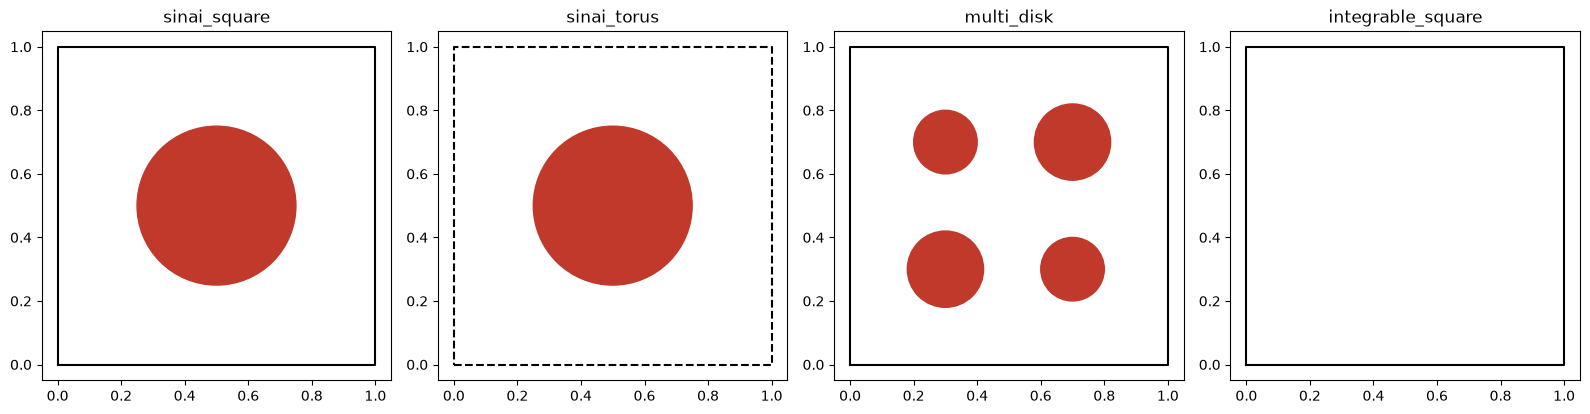

In [2]:
tables = {
    'sinai_square':      build_table('sinai_square', disk_radius=0.25),
    'sinai_torus':       build_table('sinai_torus', disk_radius=0.25),
    'multi_disk':        build_table('multi_disk', disks=[
                              Disk((0.3, 0.3), 0.12), Disk((0.7, 0.7), 0.12),
                              Disk((0.7, 0.3), 0.1), Disk((0.3, 0.7), 0.1),
                          ]),
    'integrable_square': build_table('integrable_square'),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, table) in zip(axes, tables.items()):
    table.draw(ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 2. Траектория и анимация

Одна частица на классическом бильярде Синая (квадрат + диск).

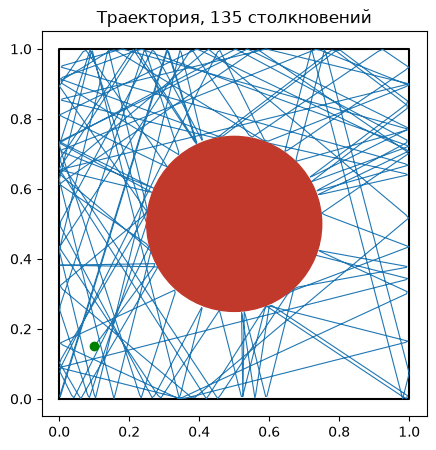

In [3]:
table = tables['sinai_square']
traj = simulate(table, pos0=[0.1, 0.15], vel0=[0.6, 0.8], n_events=4000, t_max=60.0)

fig, ax = plt.subplots(figsize=(5, 5))
plot_trajectory(table, traj, ax=ax)
ax.set_title(f'Траектория, {len(traj.collisions)} столкновений')
plt.show()

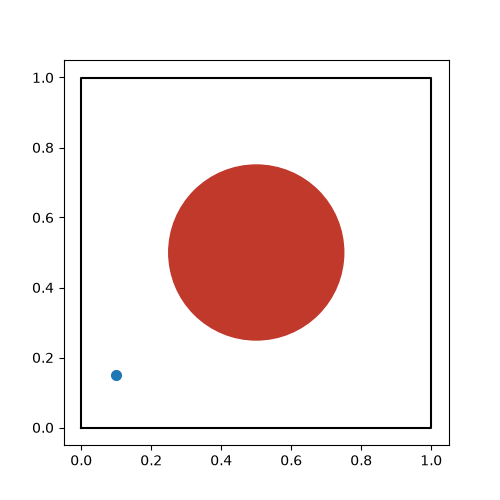

In [4]:
anim = animate_trajectories(table, traj, duration=15.0, fps=25, trail=150)
gif_path = os.path.join(DATA_DIR, 'sinai_square_animation.gif')
anim.save(gif_path, writer='pillow', fps=25)
plt.close(anim._fig)
display(Image(filename=gif_path))

### Тот же старт, три частицы рядом (наглядно про хаотичность)

Три частицы стартуют из почти одной точки с почти одинаковым углом —
наблюдайте, как быстро они расходятся.

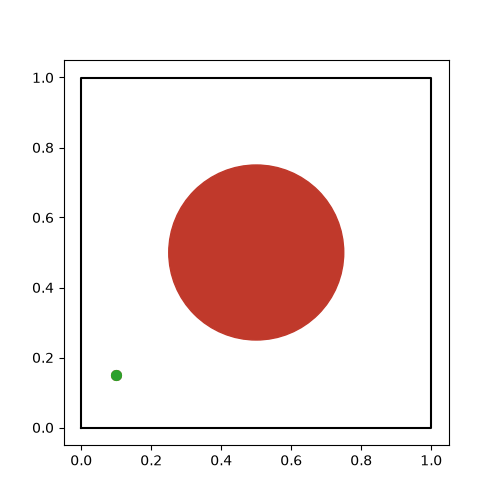

In [5]:
rng = np.random.default_rng(1)
base_pos, base_angle = np.array([0.1, 0.15]), 0.93
trajs_close = []
for k in range(3):
    da = (k - 1) * 1e-3
    v = [np.cos(base_angle + da), np.sin(base_angle + da)]
    trajs_close.append(simulate(table, base_pos, v, n_events=4000, t_max=15.0))

anim2 = animate_trajectories(table, trajs_close, duration=15.0, fps=25, trail=150)
gif_path2 = os.path.join(DATA_DIR, 'sinai_square_divergence.gif')
anim2.save(gif_path2, writer='pillow', fps=25)
plt.close(anim2._fig)
display(Image(filename=gif_path2))

## 3. Чувствительность к начальным условиям: показатель Ляпунова

Метод Беннеттина: две близкие траектории, периодическая перенормировка
расстояния между ними, усреднение ln(d/eps) по времени.

sinai_square          lambda ~ +0.9886
sinai_torus           lambda ~ +1.0707
multi_disk            lambda ~ +2.1236
integrable_square     lambda ~ +0.0000


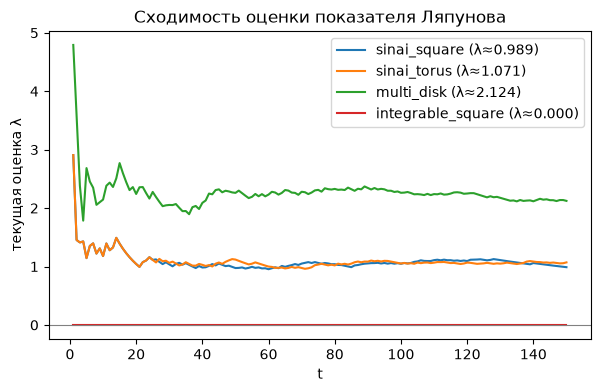

In [6]:
lyap_results = {}
for name, table in tables.items():
    lam, times, running = lyapunov_exponent(
        table, pos0=[0.11, 0.17], vel0=[0.53, 0.85], t_max=150.0, dt_rescale=1.0, seed=0,
    )
    lyap_results[name] = (lam, times, running)
    print(f'{name:20s}  lambda ~ {lam:+.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
for name, (lam, times, running) in lyap_results.items():
    ax.plot(times, running, label=f'{name} (λ≈{lam:.3f})')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel('t'); ax.set_ylabel('текущая оценка λ')
ax.legend(); ax.set_title('Сходимость оценки показателя Ляпунова')
plt.show()

### Зависимость λ от радиуса рассеивателя (квадрат Синая)

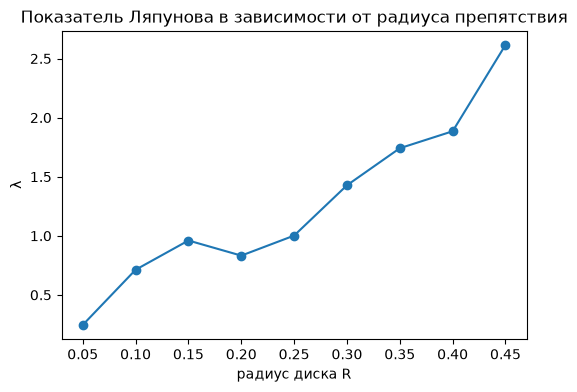

,disk_radius,lambda
0,0.05,0.245725
1,0.10,0.712650
2,0.15,0.960255
3,0.20,0.832345
4,0.25,1.001815
5,0.30,1.427456
6,0.35,1.741087
7,0.40,1.884661
8,0.45,2.615073


In [7]:
def lyap_metric(table):
    lam, _, _ = lyapunov_exponent(table, pos0=[0.06, 0.09], vel0=[0.53, 0.85], t_max=100.0, dt_rescale=1.0)
    return {'lambda': lam}

radii = np.linspace(0.05, 0.45, 9)
df_lyap_radius = sweep_parameter('disk_radius', radii, {'kind': 'sinai_square'}, lyap_metric)
df_lyap_radius.to_csv(os.path.join(DATA_DIR, 'lyapunov_vs_radius.csv'), index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df_lyap_radius['disk_radius'], df_lyap_radius['lambda'], 'o-')
ax.set_xlabel('радиус диска R'); ax.set_ylabel('λ')
ax.set_title('Показатель Ляпунова в зависимости от радиуса препятствия')
plt.show()
df_lyap_radius

## 4. Эргодичность и перемешивание

Гистограмма посещений фазового пространства (должна стремиться к равномерной
при эргодичности) + сечения Пуанкаре + автокорреляция направления скорости.

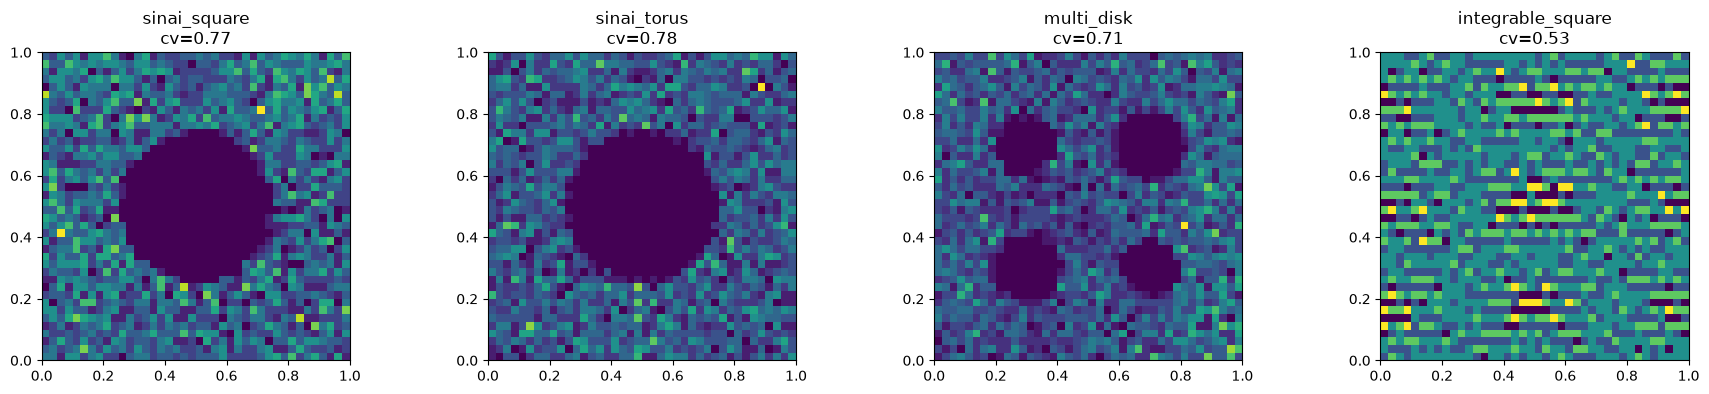

sinai_square         0.772780
sinai_torus          0.779400
multi_disk           0.714819
integrable_square    0.527447
Name: coeff_of_variation, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
uniformity = {}
for ax, (name, table) in zip(axes, tables.items()):
    long_traj = simulate(table, pos0=[0.07, 0.11], vel0=[0.61, 0.79], n_events=20000, t_max=400.0)
    H, xe, ye = position_histogram(table, long_traj, bins=40)
    uniformity[name] = uniformity_deviation(H)
    ax.imshow(H.T, origin='lower', extent=[0, table.width, 0, table.height], cmap='viridis')
    ax.set_title(f'{name}\ncv={uniformity[name]:.2f}')
plt.tight_layout()
plt.show()
pd.Series(uniformity, name='coeff_of_variation')

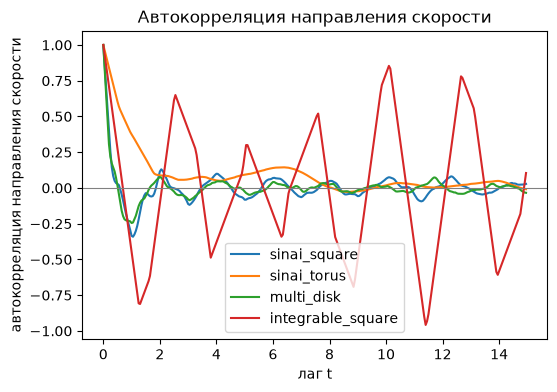

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, table in tables.items():
    long_traj = simulate(table, pos0=[0.07, 0.11], vel0=[0.61, 0.79], n_events=20000, t_max=400.0)
    lags, corr = velocity_direction_autocorrelation(long_traj, dt=0.05, max_lag=15.0)
    ax.plot(lags, corr, label=name)
ax.set_xlabel('лаг t'); ax.set_ylabel('автокорреляция направления скорости')
ax.axhline(0, color='gray', linewidth=0.8)
ax.legend(); ax.set_title('Автокорреляция направления скорости')
plt.show()

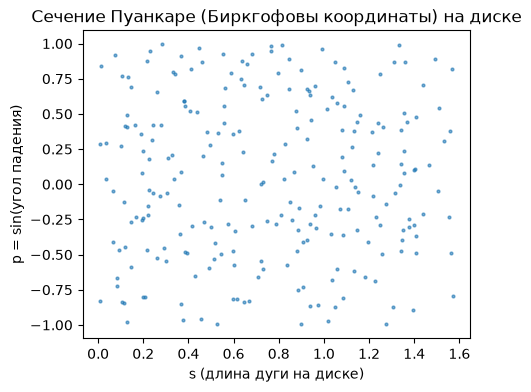

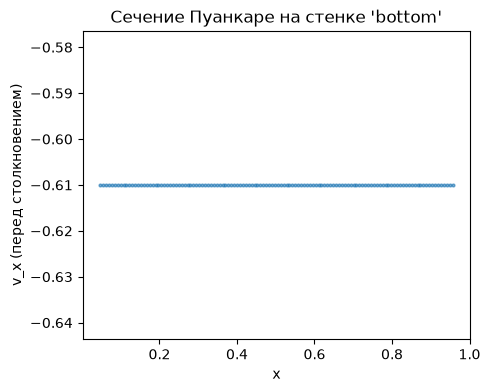

In [10]:
sinai_long = simulate(tables['sinai_square'], pos0=[0.07, 0.11], vel0=[0.61, 0.79], n_events=20000, t_max=400.0)
fig, ax = plt.subplots(figsize=(5, 4))
plot_poincare_disk(tables['sinai_square'], sinai_long, disk_idx=0, ax=ax)
plt.show()

integrable_long = simulate(tables['integrable_square'], pos0=[0.07, 0.11], vel0=[0.61, 0.6123], n_events=20000, t_max=400.0)
fig, ax = plt.subplots(figsize=(5, 4))
plot_wall_section(tables['integrable_square'], integrable_long, wall='bottom', ax=ax)
plt.show()

## 5. Статистика столкновений

Длины свободного пробега между столкновениями и распределение углов падения
на рассеиватель, для разных радиусов диска.

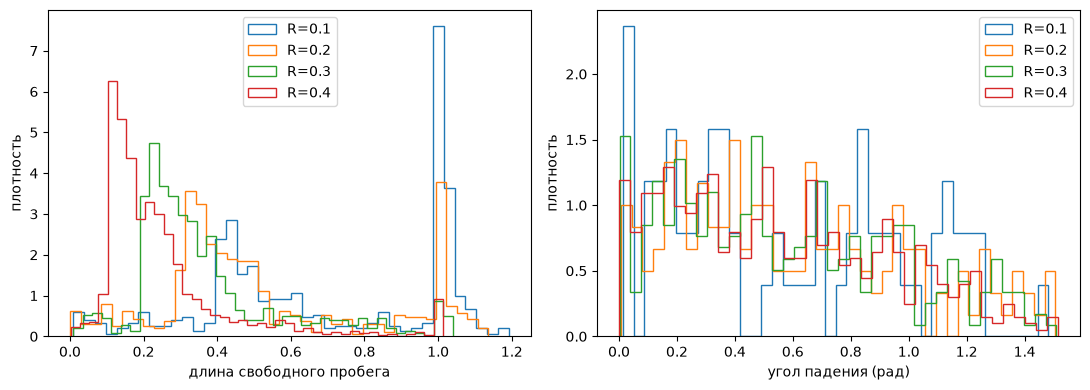

,radius,mean_free_path,n_collisions
0,0.1,0.695000,69
1,0.2,0.528626,160
2,0.3,0.373239,313
3,0.4,0.250828,532


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
radius_stats = []
for r in [0.1, 0.2, 0.3, 0.4]:
    t = build_table('sinai_square', disk_radius=r)
    traj = simulate(t, pos0=[0.03, 0.05], vel0=[0.71, 0.53], n_events=20000, t_max=400.0)
    lengths = free_path_lengths(traj)
    angles = collision_angles(traj, t)
    axes[0].hist(lengths, bins=40, histtype='step', density=True, label=f'R={r}')
    axes[1].hist(angles, bins=40, histtype='step', density=True, label=f'R={r}')
    radius_stats.append({'radius': r, 'mean_free_path': lengths.mean(), 'n_collisions': len(angles)})

axes[0].set_xlabel('длина свободного пробега'); axes[0].set_ylabel('плотность'); axes[0].legend()
axes[1].set_xlabel('угол падения (рад)'); axes[1].set_ylabel('плотность'); axes[1].legend()
plt.tight_layout()
plt.show()

df_collisions = pd.DataFrame(radius_stats)
df_collisions.to_csv(os.path.join(DATA_DIR, 'collision_stats_vs_radius.csv'), index=False)
df_collisions

## 6. Диффузия на торе

На торе с диском траектория при разворачивании (без склейки границ) должна вести
себя как случайное блуждание: MSD(t) растёт линейно, что даёт коэффициент диффузии D.

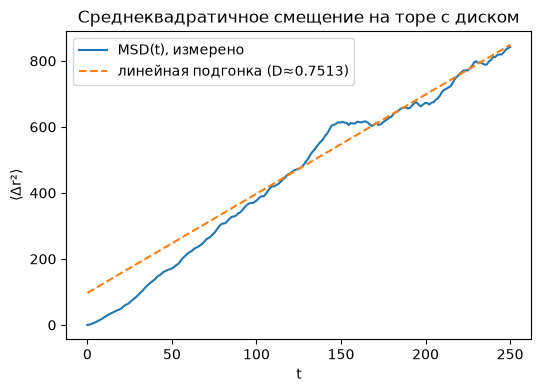

Оценка коэффициента диффузии D ≈ 0.75130


In [12]:
torus_table = tables['sinai_torus']
ensemble = run_ensemble(torus_table, n_particles=60, n_events=6000, t_max=300.0, seed=2)

times = np.linspace(0, 250.0, 200)
msd = mean_square_displacement(torus_table, ensemble, times)
D, (slope, intercept) = diffusion_coefficient(times, msd, fit_start_frac=0.3)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(times, msd, label='MSD(t), измерено')
ax.plot(times, slope * times + intercept, '--', label=f'линейная подгонка (D≈{D:.4f})')
ax.set_xlabel('t'); ax.set_ylabel('⟨Δr²⟩')
ax.legend(); ax.set_title('Среднеквадратичное смещение на торе с диском')
plt.show()

pd.DataFrame({'t': times, 'msd': msd}).to_csv(os.path.join(DATA_DIR, 'msd_torus.csv'), index=False)
print(f'Оценка коэффициента диффузии D ≈ {D:.5f}')

### Зависимость коэффициента диффузии от радиуса диска

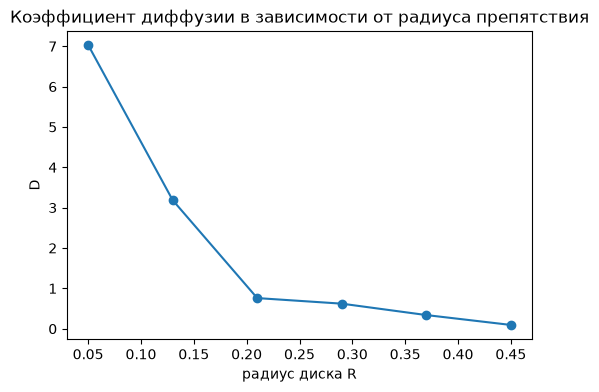

,disk_radius,D
0,0.05,7.032465
1,0.13,3.186315
2,0.21,0.759638
3,0.29,0.621272
4,0.37,0.338877
5,0.45,0.093921


In [13]:
def diffusion_metric(table):
    ens = run_ensemble(table, n_particles=40, n_events=6000, t_max=300.0, seed=3)
    t = np.linspace(0, 250.0, 150)
    m = mean_square_displacement(table, ens, t)
    D, _ = diffusion_coefficient(t, m, fit_start_frac=0.3)
    return {'D': D}

radii = np.linspace(0.05, 0.45, 6)
df_diff_radius = sweep_parameter('disk_radius', radii, {'kind': 'sinai_torus'}, diffusion_metric)
df_diff_radius.to_csv(os.path.join(DATA_DIR, 'diffusion_vs_radius.csv'), index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df_diff_radius['disk_radius'], df_diff_radius['D'], 'o-')
ax.set_xlabel('радиус диска R'); ax.set_ylabel('D')
ax.set_title('Коэффициент диффузии в зависимости от радиуса препятствия')
plt.show()
df_diff_radius

## 7. Прямоугольные бильярды: соотношение сторон

Геометрия уже поддерживает независимые `width` и `height` — квадрат был лишь
частным случаем. Здесь фиксируем ширину `width=1.0` и меняем высоту (то есть
соотношение сторон `aspect = height/width`), чтобы посмотреть, что зависит от
формы стола, а не только от радиуса диска.

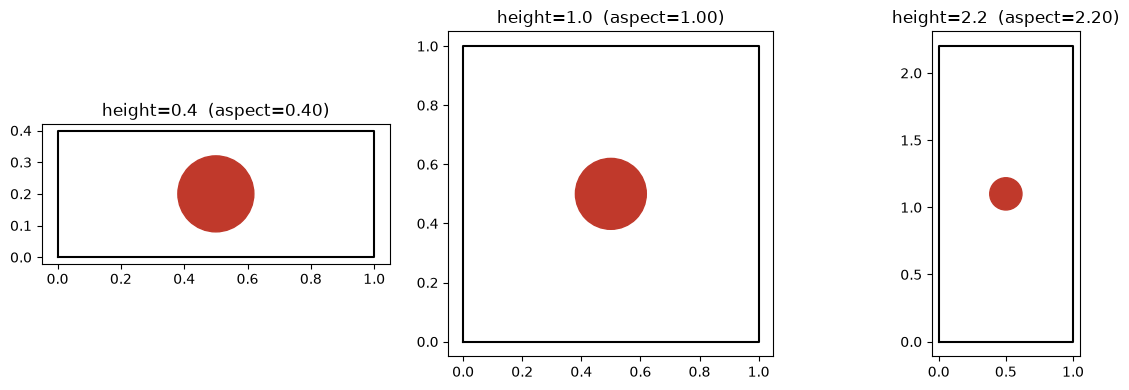

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, h in zip(axes, [0.4, 1.0, 2.2]):
    t = build_table('sinai_square', width=1.0, height=h, disk_radius=0.12)
    t.draw(ax)
    ax.set_title(f'height={h}  (aspect={h:.2f})')
plt.tight_layout()
plt.show()

### Показатель Ляпунова в зависимости от соотношения сторон (радиус диска фиксирован)

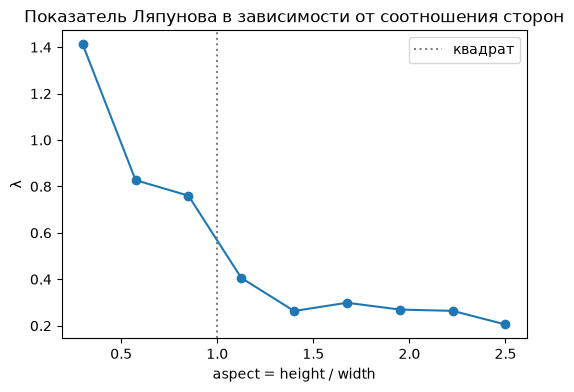

,height,lambda,aspect
0,0.300,1.411317,0.300
1,0.575,0.826974,0.575
2,0.850,0.760006,0.850
3,1.125,0.405703,1.125
4,1.400,0.263201,1.400
5,1.675,0.298744,1.675
6,1.950,0.269408,1.950
7,2.225,0.263896,2.225
8,2.500,0.205054,2.500


In [15]:
def lyap_metric_rect(table):
    lam, _, _ = lyapunov_exponent(table, pos0=[0.05, 0.05], vel0=[0.53, 0.85], t_max=100.0, dt_rescale=1.0)
    return {'lambda': lam}

heights = np.linspace(0.3, 2.5, 9)
df_lyap_aspect = sweep_parameter(
    'height', heights, {'kind': 'sinai_square', 'width': 1.0, 'disk_radius': 0.12}, lyap_metric_rect,
)
df_lyap_aspect['aspect'] = df_lyap_aspect['height'] / 1.0
df_lyap_aspect.to_csv(os.path.join(DATA_DIR, 'lyapunov_vs_aspect_ratio.csv'), index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df_lyap_aspect['aspect'], df_lyap_aspect['lambda'], 'o-')
ax.axvline(1.0, color='gray', linestyle=':', label='квадрат')
ax.set_xlabel('aspect = height / width'); ax.set_ylabel('λ')
ax.legend(); ax.set_title('Показатель Ляпунова в зависимости от соотношения сторон')
plt.show()
df_lyap_aspect

### Анизотропная диффузия на прямоугольном торе

На торе диффузия вдоль `x` и вдоль `y` в общем случае не обязана совпадать.
Дополнительно считаем долю "свободного канала" в каждом направлении — полосы,
которую диск вообще не перекрывает поперёк соответствующей оси (доля высоты,
свободная от диска, определяет беспрепятственный канал вдоль `x`, и наоборот).
Это связано с эффектом **бесконечного горизонта** в периодическом газе Лоренца:
одного диска на ячейку недостаточно, чтобы перекрыть все прямые каналы, и вдоль
такого канала перемещение может быть быстрее простой диффузии.

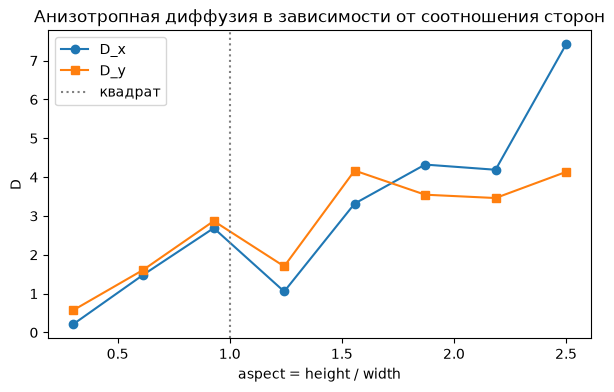

,height,D_x,D_y,free_channel_frac_x,free_channel_frac_y,aspect
0,0.300000,0.204552,0.566440,0.200000,0.76,0.300000
1,0.614286,1.485268,1.612361,0.609302,0.76,0.614286
2,0.928571,2.687032,2.869030,0.741538,0.76,0.928571
3,1.242857,1.054272,1.701910,0.806897,0.76,1.242857
4,1.557143,3.318005,4.168586,0.845872,0.76,1.557143
5,1.871429,4.322709,3.547246,0.871756,0.76,1.871429
6,2.185714,4.189246,3.461201,0.890196,0.76,2.185714
7,2.500000,7.414940,4.133236,0.904000,0.76,2.500000


In [16]:
def diffusion_aniso_metric(table):
    ens = run_ensemble(table, n_particles=40, n_events=6000, t_max=300.0, seed=4)
    t = np.linspace(0, 250.0, 150)
    msd_x, msd_y = mean_square_displacement_xy(table, ens, t)
    D_x, D_y = diffusion_coefficients_xy(t, msd_x, msd_y)
    R = table.disks[0].radius
    return {
        'D_x': D_x, 'D_y': D_y,
        'free_channel_frac_x': (table.height - 2 * R) / table.height,
        'free_channel_frac_y': (table.width - 2 * R) / table.width,
    }

heights = np.linspace(0.3, 2.5, 8)
df_aniso = sweep_parameter(
    'height', heights, {'kind': 'sinai_torus', 'width': 1.0, 'disk_radius': 0.12}, diffusion_aniso_metric,
)
df_aniso['aspect'] = df_aniso['height'] / 1.0
df_aniso.to_csv(os.path.join(DATA_DIR, 'diffusion_anisotropy_vs_aspect_ratio.csv'), index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_aniso['aspect'], df_aniso['D_x'], 'o-', label='D_x')
ax.plot(df_aniso['aspect'], df_aniso['D_y'], 's-', label='D_y')
ax.axvline(1.0, color='gray', linestyle=':', label='квадрат')
ax.set_xlabel('aspect = height / width'); ax.set_ylabel('D')
ax.legend(); ax.set_title('Анизотропная диффузия в зависимости от соотношения сторон')
plt.show()
df_aniso

### Резонансы в интегрируемом прямоугольнике: почему форма стола важна даже без диска

Классический результат теории бильярдов: в прямоугольнике `w × h` траектория с
компонентами скорости `(vx, vy)` периодична **тогда и только тогда**, когда
величина `(vy/vx) * (w/h)` рациональна — иначе траектория квазипериодична и
плотно заметает весь стол. Обратите внимание: это зависит от *комбинации* угла
и соотношения сторон, а не от угла самого по себе.

(vy/vx)*(w/h) для случая A (45°):        0.707107  -> иррационально, ждём квазипериодичность
(vy/vx)*(w/h) для случая B (arctan√2):   1.000000  -> рационально (=1), ждём периодичность


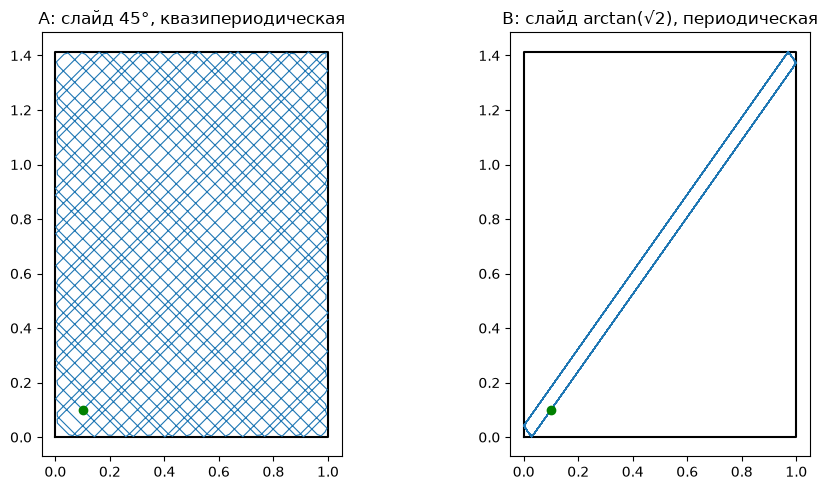

In [17]:
w, h = 1.0, np.sqrt(2)  # иррациональное соотношение сторон
rect = build_table('integrable_square', width=w, height=h)

vel_a = np.array([1.0, 1.0]); vel_a /= np.linalg.norm(vel_a)          # "красивый" угол 45°
vel_b = np.array([1.0, np.sqrt(2)]); vel_b /= np.linalg.norm(vel_b)   # "некрасивый" угол

ratio_a = (vel_a[1] / vel_a[0]) * (w / h)
ratio_b = (vel_b[1] / vel_b[0]) * (w / h)
print(f'(vy/vx)*(w/h) для случая A (45°):        {ratio_a:.6f}  -> иррационально, ждём квазипериодичность')
print(f'(vy/vx)*(w/h) для случая B (arctan√2):   {ratio_b:.6f}  -> рационально (=1), ждём периодичность')

traj_a = simulate(rect, pos0=[0.1, 0.1], vel0=vel_a, n_events=3000, t_max=80.0)
traj_b = simulate(rect, pos0=[0.1, 0.1], vel0=vel_b, n_events=3000, t_max=80.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_trajectory(rect, traj_a, ax=axes[0]); axes[0].set_title('A: слайд 45°, квазипериодическая')
plot_trajectory(rect, traj_b, ax=axes[1]); axes[1].set_title('B: слайд arctan(√2), периодическая')
plt.tight_layout()
plt.show()

## 8. Экспорт данных

Полные траектории и сводные таблицы сохраняются в `../data/` для дальнейшего
анализа (Excel/pandas/R/что угодно).

In [18]:
export_trajectory_csv(traj, os.path.join(DATA_DIR, 'trajectory_sinai_square.csv'))
export_trajectory_csv(sinai_long, os.path.join(DATA_DIR, 'trajectory_sinai_square_long.csv'))
export_trajectory_csv(ensemble[0], os.path.join(DATA_DIR, 'trajectory_sinai_torus_particle0.csv'))

print('Сохранённые файлы в data/:')
for f in sorted(os.listdir(DATA_DIR)):
    print(' -', f)

Сохранённые файлы в data/:
 - collision_stats_vs_radius.csv
 - diffusion_anisotropy_vs_aspect_ratio.csv
 - diffusion_vs_radius.csv
 - lyapunov_vs_aspect_ratio.csv
 - lyapunov_vs_radius.csv
 - msd_torus.csv
 - sinai_square_animation.gif
 - sinai_square_divergence.gif
 - trajectory_sinai_square.csv
 - trajectory_sinai_square_long.csv
 - trajectory_sinai_torus_particle0.csv


## 9. Выводы

*(Заполнить самостоятельно по результатам выше.)*

Наводящие вопросы, которые стоит раскрыть в выводах:

- Как знак и величина λ отличаются между бильярдом Синая (квадрат/тор с диском)
  и интегрируемым случаем (пустой квадрат)? Согласуется ли это с теорией
  (бильярд Синая — K-система с положительной энтропией, интегрируемый
  бильярд — нулевая энтропия)?
- Как λ и коэффициент диффузии D меняются с радиусом рассеивателя? Есть ли
  область, где зависимость близка к монотонной, и можно ли объяснить это через
  среднюю длину свободного пробега?
- Насколько равномерна гистограмма посещений (`coeff_of_variation`) для каждого
  варианта таблицы — подтверждает ли она эргодичность бильярда Синая по
  сравнению с интегрируемым случаем?
- Как быстро спадает автокорреляция направления скорости в хаотическом и
  интегрируемом случаях? Что это говорит о перемешивании (mixing)?
- Что показывает сечение Пуанкаре: заполняет ли траектория бильярда Синая
  фазовую плоскость (s, p) плотно, в отличие от регулярных линий интегрируемого
  случая?
- Как распределены длины свободного пробега и углы падения на диск — совпадает
  ли форма распределения при разных радиусах, меняется ли только масштаб?
- Похоже ли поведение MSD(t) на торе на классическую диффузию (линейный рост)
  на всех временных масштабах, или только начиная с какого-то момента? Почему?
- Как λ меняется с соотношением сторон при фиксированном радиусе диска — есть
  ли немонотонность, и если да, чем она объясняется?
- В разделе про анизотропную диффузию D_x и D_y меняются местами при каком-то
  соотношении сторон (кроссовер) — совпадает ли точка кроссовера с пересечением
  `free_channel_frac_x` и `free_channel_frac_y`? Что это говорит о механизме,
  который определяет, в каком направлении диффузия быстрее?
- В примере с резонансами (раздел 7): убедитесь по значениям `ratio_a`/`ratio_b`
  в коде, что критерий периодичности выполняется, и объясните своими словами,
  почему "простой" угол 45° даёт непериодическую траекторию, а "сложный"
  arctan(√2) — периодическую, именно на этом столе.